# Modeling

### 1: Create Train/Test Split
Why not train_test_split()?
<br>
Suppose your data looks like this:
<br>
Time	Bike Count<br>
Jan	100<br>
Feb	120<br>
Mar	140<br>
Apr	180<br>
May	210<br>
<br>
If we use....
train_test_split()

it might create
Training....
Jan,
Mar,
May Testing Feb,
Apr

Now the model has already seen May while trying to predict February.

That is impossible in the real world.
This is why random splitting causes data leakage in time-series.

### Use TimeSeriesSplit

Instead, the training data always comes before the testing data.

Fold 1

Train:
Jan Feb Mar<br>
Test:
Apr<br>
<br>
Fold 2

Train:
Jan Feb Mar Apr<br>
Test:
May

This mimics real forecasting.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit

In [4]:
df = pd.read_csv("data/processed/hour_featured.csv")
df.head()

,datetime,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,...,month_cos,lag_1,lag_24,lag_168,rolling_mean_24,rolling_median_24,rolling_std_24,is_peak_hour,temp_hr,weather_hr
0,2011-01-08 07:00:00,1,0,1,7,0,6,0,2,0.16,...,0.866025,2.0,84.0,16.0,60.083333,50.5,56.721989,1,1.12,14
1,2011-01-08 08:00:00,1,0,1,8,0,6,0,3,0.16,...,0.866025,9.0,210.0,40.0,51.958333,44.5,47.536237,1,1.28,24
2,2011-01-08 09:00:00,1,0,1,9,0,6,0,3,0.16,...,0.866025,15.0,134.0,32.0,47.208333,37.5,44.585998,1,1.44,27
3,2011-01-08 10:00:00,1,0,1,10,0,6,0,2,0.18,...,0.866025,20.0,63.0,13.0,47.125000,37.5,44.557059,0,1.80,20
4,2011-01-08 11:00:00,1,0,1,11,0,6,0,2,0.20,...,0.866025,61.0,67.0,1.0,46.916667,37.5,44.471698,0,2.20,22


#### 1.Separate Features and Target


In [5]:
#target
y = df["cnt"]

In [6]:
#features
X = df.drop(columns=["cnt"])

In [7]:
print(X.shape)
print(y.shape)

(17211, 28)
(17211,)


#### 2. Create TimeSeriesSplit

We'll use 5 folds.

In [8]:
tscv = TimeSeriesSplit(n_splits=5)

In [9]:
for fold, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):

    print(f"Fold {fold}")

    print("Train:", train_idx[0], "to", train_idx[-1])

    print("Test :", test_idx[0], "to", test_idx[-1])

    print("-"*40)

Fold 1
Train: 0 to 2870
Test : 2871 to 5738
----------------------------------------
Fold 2
Train: 0 to 5738
Test : 5739 to 8606
----------------------------------------
Fold 3
Train: 0 to 8606
Test : 8607 to 11474
----------------------------------------
Fold 4
Train: 0 to 11474
Test : 11475 to 14342
----------------------------------------
Fold 5
Train: 0 to 14342
Test : 14343 to 17210
----------------------------------------


The training set keeps growing.<br>
This is called an expanding window.

#### 3. Visualize the Splits

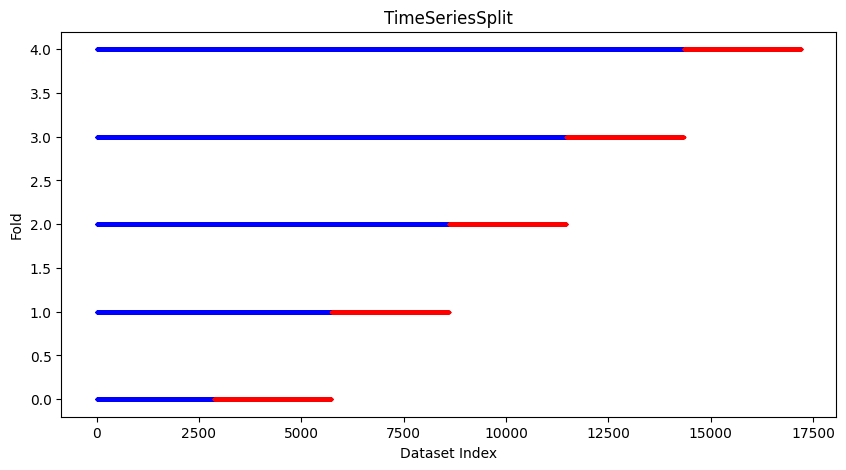

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):

    plt.scatter(train_idx,
                [fold]*len(train_idx),
                color="blue",
                s=2)

    plt.scatter(test_idx,
                [fold]*len(test_idx),
                color="red",
                s=2)

plt.xlabel("Dataset Index")
plt.ylabel("Fold")
plt.title("TimeSeriesSplit")
plt.show()

🔵 Blue = Training data
🔴 Red = Testing data<br>
Each fold trains on all previous observations and tests on future observations.

Unlike random train-test splitting, TimeSeriesSplit preserves the chronological order of observations. Each fold trains on past data and evaluates on future data, preventing data leakage and providing a realistic estimate of model performance in real-world forecasting scenarios.

## Baseline Model

Why do we need baselines?

Imagine your XGBoost model gives MAE = 42<br>
Is that good?<br>
You don't know unless you compare it with something simple.<br>
That's why we create baseline models first.

### Baseline 1 — Yesterday's Same Hour Demand (Naïve-24)
Idea:

Suppose you want to predict

Tuesday 3 PM

A simple assumption is:<br>
"Bike demand will be the same as yesterday at 3 PM."

Example

Time	Bike Count<br>
Monday 3 PM	250<br>
Tuesday 3 PM	?

Prediction

250<br>
This is called the Naïve-24 baseline.

In [11]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [12]:
prediction = df["lag_24"]
actual = df["cnt"]

In [13]:
y_true = df["cnt"]

y_pred = df["lag_24"]

In [14]:
#drop na
baseline1 = pd.DataFrame({
    "actual": y_true,
    "pred": y_pred
}).dropna()

In [23]:
#compute matrix

mae_naive = mean_absolute_error(
    baseline1["actual"],
    baseline1["pred"]
)

rmse_naive = np.sqrt(
    mean_squared_error(
        baseline1["actual"],
        baseline1["pred"]
    )
)

r2_naive = r2_score(
    baseline1["actual"],
    baseline1["pred"]
)

print("MAE :", mae_naive)
print("RMSE:", rmse_naive)
print("R²  :", r2_naive)

MAE : 65.36029283597699
RMSE: 110.52741336266935
R²  : 0.6300429720034595


The Naïve-24 baseline predicts the current hour's demand using the bike demand from the same hour on the previous day. It provides a strong benchmark because bike-sharing demand follows daily usage patterns.

#### Baseline 2 — Average Demand of Same Hour

Now we'll make a smarter baseline.
Instead of yesterday,
"What is the average demand at this hour?"

Example

Hour	Bike Count<br>
8 AM	300<br>
8 AM	320<br>
8 AM	340<br>
8 AM	310<br>

Average: 
317.5

Every future....8 AM  will predict 317.5

In [16]:
#calculate hourly avg
hour_mean = (
    df.groupby("hr")["cnt"]
      .mean()
)

In [17]:
print(hour_mean)

hr
0      54.356546
1      33.617318
2      23.007062
3      11.740634
4       6.409289
5      20.050704
6      76.648536
7     213.530556
8     361.150000
9     220.618056
10    174.884722
11    209.602778
12    255.029126
13    255.375346
14    242.610803
15    252.952909
16    314.188105
17    464.467497
18    428.418863
19    313.676838
20    227.707351
21    173.578363
22    132.302358
23     88.507628
Name: cnt, dtype: float64


In [18]:
## Predict
# Map every hour to its average demand.

df["hour_mean_pred"] = (
    df["hr"]
      .map(hour_mean)
)

In [19]:
df[
[
"hr",
"cnt",
"hour_mean_pred"
]
].head()

,hr,cnt,hour_mean_pred
0,7,9,213.530556
1,8,15,361.150000
2,9,20,220.618056
3,10,61,174.884722
4,11,62,209.602778


In [24]:
mae_hour = mean_absolute_error(
    df["cnt"],
    df["hour_mean_pred"]
)

rmse_hour = np.sqrt(
    mean_squared_error(
        df["cnt"],
        df["hour_mean_pred"]
    )
)

r2_hour = r2_score(
    df["cnt"],
    df["hour_mean_pred"]
)

print("MAE :", mae_hour)
print("RMSE:", rmse_hour)
print("R² :", r2_hour)

MAE : 87.74303041356873
RMSE: 127.68479550610084
R² : 0.5062698602709195


This baseline predicts bike demand using the historical average demand for each hour of the day. It captures the daily demand pattern but ignores weather, seasonality, holidays, and recent demand trends.

In [25]:
#compare baseline

results = pd.DataFrame({
    "Model":[
        "Naive-24",
        "Hour Mean"
    ],
    "MAE":[
        mae_naive,
        mae_hour
    ],
    "RMSE":[
        rmse_naive,
        rmse_hour
    ],
    "R2":[
        r2_naive,
        r2_hour
    ]
})

results

,Model,MAE,RMSE,R2
0,Naive-24,65.360293,110.527413,0.630043
1,Hour Mean,87.743030,127.684796,0.506270


Naïve-24 wins because yesterday's demand is more informative than the long-term hourly average.

Two baseline forecasting models were evaluated. The Naïve-24 baseline, which predicts demand using the same hour from the previous day, outperformed the Hour Mean baseline, demonstrating that recent historical demand provides a stronger signal than the average hourly demand alone. These baselines serve as reference points for evaluating advanced machine learning models.